In [3]:
import itertools
from ast import literal_eval
import os

import numpy as np
import pandas as pd
from scipy.integrate import trapezoid

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MaxNLocator
import seaborn as sns

from mg_sampling import PROJECT_DIR
from mg_sampling.constants import RT
from mg_sampling.tools import read_plumed, read_plumed_fes, range_to_edges, edges_to_range, finitemin, finitemax, block_analysis, read_wsv, to_wsv
from mg_sampling.bias import bias_fn

LABELS = {
    'amber_tip3p': "Amber/TIP3P",
    'mMg_tip3p': "microMg/TIP3P",
    'nMg_tip3p': "nanoMg/TIP3P", 
    'mMg_opc': "microMg/OPC",
    'ecc_spce': "AmberECC/SPCE",
}

FORCEFIELDS_ARCHIVE = ['amber_tip3p', 'mMg_tip3p', 'nMg_tip3p', 'mMg_opc', 'ecc_spce']
FORCEFIELDS = ['mMg_tip3p']

os.makedirs('figures/biasfitting', exist_ok=True)
os.makedirs('figures/biasfitting/archive', exist_ok=True)

### Fit bias

In [13]:
from mg_sampling.bias import fit_bias, bias_fn, ASSOCIATIVE_BOUNDS, ASSOCIATIVE_P_0, PARAMS_NAMES
from mg_sampling.classes import MetadSim

def associative_mask(x, y):
    X = x - y + 6
    Y = x + y - 6
    return  (X > 0) * (X < 2) * (Y > 0) * (Y < 2)

def associative_loss_fn(sim: MetadSim, bias_fn, params):
    """
    Loss for flattening the associative pathway.
    - FES restricted to the (0 < X < 2, 0 < Y < 2) square is projected on X
    - Trend between the two minima is substracted
    - Loss targets barrier height (max - min)
    - Regularized with relative entropy DKL(new_weights, old_weights)
    """
    X_edges = np.linspace(0, 2, 2*20+1)
    X_range = edges_to_range(X_edges)
    mask = associative_mask(sim.x, sim.y)
    bias_weights = np.exp(-bias_fn(sim.x, sim.y, *params)/RT) * mask
    ρX, _ = np.histogram(sim.X, bins=X_edges, density=True, weights=sim.weights*bias_weights)
    FX = -RT*np.log(ρX)
    # Remove trend
    imid = len(FX) // 2
    i1, i2 = np.argmin(FX[:imid]), np.argmin(FX[imid:]) + imid
    FX -= X_range * (FX[i2] - FX[i1])/(X_range[i2] - X_range[i1])
    # new_weights = sim.weights * bias_weights
    # rel_entropy = entropy(new_weights, sim.weights * mask)
    return np.max(FX) - np.min(FX)

for ff in FORCEFIELDS:
    sim = MetadSim(PROJECT_DIR / f'metad/op_{ff}')
    np.random.seed(42)
    res = fit_bias(sim, bias_fn, associative_loss_fn, ASSOCIATIVE_P_0, bounds=ASSOCIATIVE_BOUNDS)
    print(res)
    to_wsv(
        pd.DataFrame([res], columns=PARAMS_NAMES),
        PROJECT_DIR / f'metad/op_{ff}/bias_params.wsv',
    )

/scratch_local/ipykernel_3639915/2221674500.py:22: RuntimeWarning: divide by zero encountered in log
  FX = -RT*np.log(ρX)
/scratch_local/ipykernel_3639915/2221674500.py:26: RuntimeWarning: invalid value encountered in subtract
  FX -= X_range * (FX[i2] - FX[i1])/(X_range[i2] - X_range[i1])


  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 4.659766390698318
        x: [ 3.831e+01  1.010e-01  2.875e-01]
      nit: 28
      jac: [-5.000e-01 -3.562e+01  3.993e-01]
     nfev: 784
     njev: 196
 hess_inv: <3x3 LbfgsInvHessProduct with dtype=float64>
[38.30790301  0.10098029  0.28752285]


/leonardo_work/EUHPC_R02_136/Olivier/mg_sampling/.venv/lib/python3.11/site-packages/scipy/optimize/_numdiff.py:596: RuntimeWarning: invalid value encountered in subtract
  df = fun(x1) - f0


### Plot fitted biases

In [14]:
def plot_bias_on_fes(path, ax):

    colvar = read_plumed(f'{path}/COLVAR')
    params = read_wsv(f'{path}/bias_params.wsv').iloc[0]

    X_edges = np.linspace(0, 2, 41)
    Y_edges = np.linspace(0, 2, 41)
    bins = (X_edges, Y_edges)
    X_range = edges_to_range(X_edges)
    Y_range = edges_to_range(Y_edges)

    bias = colvar['metad.bias']  # kJ/mol
    weights = np.exp(bias/RT)

    # Remove nop == 0
    X = colvar['nop'] - colvar['now'] + 6
    Y = colvar['nop'] + colvar['now'] - 6
    weights[X <= 0] = 0
    weights[X > 2] = 0
    weights[Y <= 0] = 0
    weights[Y > 2] = 0

    ρ_avg, _, _ = np.histogram2d(X, Y, bins=bins, density=True, weights=weights)
    with np.errstate(divide='ignore'):
        fes = -np.log(ρ_avg)
    fes -= finitemin(fes)

    extent = [*X_edges[[0, -1]], *Y_edges[[0, -1]]]
    levels = np.arange(0, finitemax(fes), 2)

    # im = ax.imshow(fes.T, extent=extent, origin='lower', aspect=1, cmap='RdPu_r')
    cf = ax.contour(fes.T, colors=['black'], linewidths=[1, 0.2], extent=extent, levels=levels)

    # Show bias
    XX, YY = np.meshgrid(X_range, Y_range, indexing='ij')
    u = bias_fn((XX + YY)/2, YY - (XX+YY)/2 + 6, *params) / RT
    im = ax.imshow(u.T, extent=extent, origin='lower', aspect=1, cmap='Reds_r')
    cbar = plt.colorbar(im, ax=ax, fraction=0.05)
    cf = ax.contour(u.T, colors=['black'], linewidths=0.5, extent=extent, levels=-levels[::-1])
    cbar.add_lines(cf)
    cbar.set_label("$U_\mathrm{bias}$ [$k_\mathrm{B}T$]")

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.tick_params(labelbottom=True)

    ax.set_xlabel("$\Delta (n_\mathrm{O_P} - n_\mathrm{O_W})$")
    ax.set_ylabel("$\Delta (n_\mathrm{O_P} + n_\mathrm{O_W})$")
    ax.grid(False)

def plot_barrier_projection(path, ax):

    colvar = read_plumed(f'{path}/COLVAR')
    params = read_wsv(f'{path}/bias_params.wsv').iloc[0]

    X_edges = np.linspace(0, 2, 41)
    Y_edges = np.linspace(0, 2, 41)
    bins = (X_edges, Y_edges)
    X_range = edges_to_range(X_edges)
    Y_range = edges_to_range(Y_edges)

    bias = colvar['metad.bias']  # kJ/mol
    weights = np.exp(bias/RT)

    # Remove nop == 0
    x = colvar['nop']
    y = colvar['now']
    X = colvar['nop'] - colvar['now'] + 6
    Y = colvar['nop'] + colvar['now'] - 6
    weights[X <= 0] = 0
    weights[X > 2] = 0
    weights[Y <= 0] = 0
    weights[Y > 2] = 0

    ρ_avg, _, _ = np.histogram2d(X, Y, bins=bins, density=True, weights=weights)
    with np.errstate(divide='ignore'):
        fes = -np.log(ρ_avg)
    fes -= finitemin(fes)

    # Block analysis for error on FES projection
    def get_F_X(X, Y, weights):
        ρ_avg, _, _ = np.histogram2d(X, Y, bins=bins, density=True, weights=weights)
        ρ_X = trapezoid(ρ_avg, Y_range, axis=1)
        F_X = -np.log(ρ_X)
        F_X -= finitemin(F_X)
        return F_X

    F_X_mean, F_X_stderr = block_analysis(X, Y, weights, func=get_F_X, n_blocks=5, skip=1)
    ax2.plot(X_range, F_X_mean, color='black')
    ax2.fill_between(X_range, F_X_mean - 1.96*F_X_stderr, F_X_mean + 1.96*F_X_stderr, alpha=0.3, facecolor='black')

    # Bias weighted
    weights = weights * np.exp(-bias_fn(x, y, *params)/RT)
    F_X_mean, F_X_stderr = block_analysis(X, Y, weights, func=get_F_X, n_blocks=5, skip=1)
    ax2.plot(X_range, F_X_mean, color='red')
    ax2.fill_between(X_range, F_X_mean - 1.96*F_X_stderr, F_X_mean + 1.96*F_X_stderr, alpha=0.3, facecolor='red')

    ax2.set_xlabel("$\Delta (n_\mathrm{O_P} - n_\mathrm{O_W})$")
    ax2.set_ylabel("FES [$k_\mathrm{B}T$]")

/scratch_local/ipykernel_1085520/4231850353.py:24: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_1085520/4231850353.py:75: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_1085520/4231850353.py:24: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_1085520/4231850353.py:75: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_1085520/4231850353.py:24: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_1085520/4231850353.py:75: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_1085520/4231850353.py:24: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_1085520/4231850353.py:75: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)


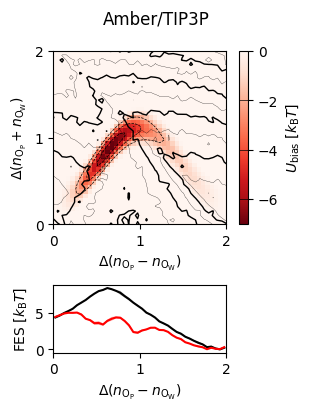

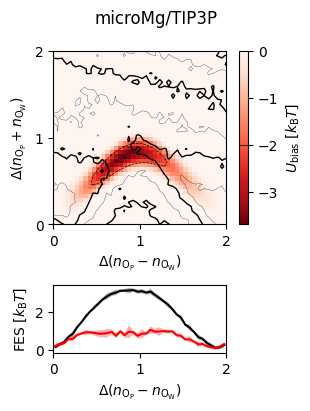

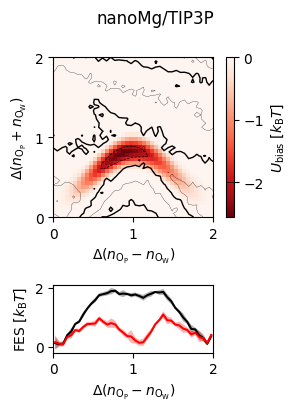

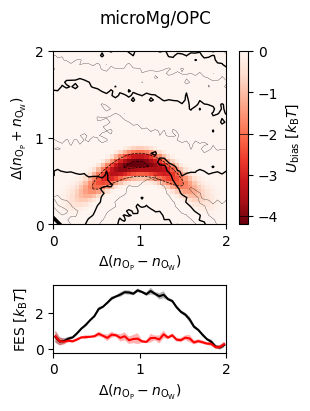

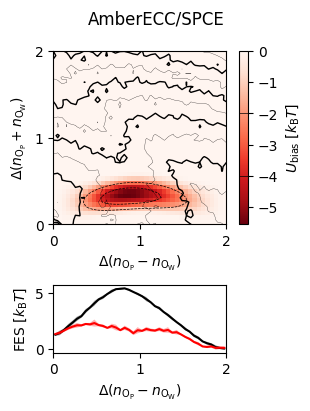

In [3]:
for ff in FORCEFIELDS_ARCHIVE:
    fig, (ax1, ax2) = plt.subplots(nrows=2, height_ratios=(3, 1), sharex=True, figsize=(3, 4), constrained_layout=True)
    plot_bias_on_fes(PROJECT_DIR / f'metad/archive/op_{ff}', ax1)
    plot_barrier_projection(PROJECT_DIR / f'metad/archive/op_{ff}', ax2)
    fig.suptitle(LABELS[ff])
    plt.savefig(f'figures/biasfitting/archive/barrier_{ff}.pdf')

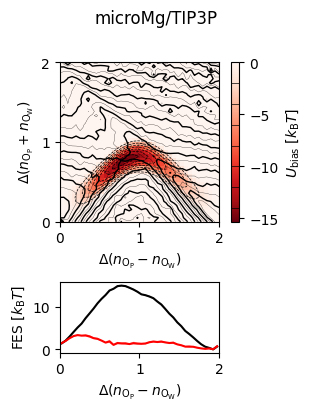

In [15]:
for ff in FORCEFIELDS:
    fig, (ax1, ax2) = plt.subplots(nrows=2, height_ratios=(3, 1), sharex=True, figsize=(3, 4), constrained_layout=True)
    plot_bias_on_fes(PROJECT_DIR / f'metad/op_{ff}', ax1)
    plot_barrier_projection(PROJECT_DIR / f'metad/op_{ff}', ax2)
    fig.suptitle(LABELS[ff])
    plt.savefig(f'figures/biasfitting/barrier_{ff}.pdf')

### Barrier through MFEP

In [17]:
from mg_sampling.stringbase import Landscape, String

def plot_bias_on_fes_mfep(path, ax):

    colvar = read_plumed(f'{path}/COLVAR')
    params = read_wsv(f'{path}/bias_params.wsv').iloc[0]

    X_edges = np.linspace(0, 2, 41)
    Y_edges = np.linspace(0, 2, 41)
    bins = (X_edges, Y_edges)
    X_range = edges_to_range(X_edges)
    Y_range = edges_to_range(Y_edges)

    bias = colvar['metad.bias']  # kJ/mol
    weights = np.exp(bias/RT)

    # Remove nop == 0
    X = colvar['nop'] - colvar['now'] + 6
    Y = colvar['nop'] + colvar['now'] - 6
    weights[X <= 0] = 0
    weights[X > 2] = 0
    weights[Y <= 0] = 0
    weights[Y > 2] = 0

    ρ_avg, _, _ = np.histogram2d(X, Y, bins=bins, density=True, weights=weights)
    with np.errstate(divide='ignore'):
        fes = -np.log(ρ_avg)
    fes -= finitemin(fes)

    extent = [*X_edges[[0, -1]], *Y_edges[[0, -1]]]
    levels = np.arange(0, finitemax(fes), 2)

    # im = ax.imshow(fes.T, extent=extent, origin='lower', aspect=1, cmap='RdPu_r')
    cf = ax.contour(fes.T, colors=['black'], linewidths=[1, 0.2], extent=extent, levels=levels)

    # Show bias
    XX, YY = np.meshgrid(X_range, Y_range, indexing='ij')
    u = bias_fn((XX + YY)/2, YY - (XX+YY)/2 + 6, *params) / RT
    im = ax.imshow(u.T, extent=extent, origin='lower', aspect=1, cmap='Reds_r')
    cbar = plt.colorbar(im, ax=ax, fraction=0.05)
    cf = ax.contour(u.T, colors=['black'], linewidths=0.5, extent=extent, levels=-levels[::-1])
    cbar.add_lines(cf)
    cbar.set_label("$U_\mathrm{bias}$ [$k_\mathrm{B}T$]")

    # find MFEP
    # clip fes to finite values to avoid problems
    fes = np.clip(fes, finitemin(fes), finitemax(fes))
    landscape = Landscape(X_range, Y_range, fes.T + u.T)
    #string = String([0.1, 0.5, 1, 1.5, 1.9], [0.1, 0.5, 1, 0.5, 0.1], fixed=False)
    N = 20
    string = String.from_interpolation(0.05, 0.05, 1.95, 0.05, N, fixed=False)
    string.reparameterize(N)
    ax.plot(string.xdata, string.ydata, marker='.', color='gray')
    np.random.seed(42)
    for σ in np.linspace(0.05, 0, 1000):
        string.random_walk(σ, σ)
        string.drift(landscape, 0.02)
        string.xdata[0] = 0.05
        string.xdata[-1] = 1.95
        string.ydata = np.clip(string.ydata, 0, 2)
        string.untangle()
        string.reparameterize(N)

    ax.plot(string.xdata, string.ydata, marker='.', color='black')

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.tick_params(labelbottom=True)

    ax.set_xlabel("$\Delta (n_\mathrm{O_P} - n_\mathrm{O_W})$")
    ax.set_ylabel("$\Delta (n_\mathrm{O_P} + n_\mathrm{O_W})$")
    ax.grid(False)


def plot_barrier_mfep(path, ax):

    colvar = read_plumed(f'{path}/COLVAR')
    params = read_wsv(f'{path}/bias_params.wsv').iloc[0]

    X_edges = np.linspace(0, 2, 41)
    Y_edges = np.linspace(0, 2, 41)
    bins = (X_edges, Y_edges)
    X_range = edges_to_range(X_edges)
    Y_range = edges_to_range(Y_edges)

    bias = colvar['metad.bias']  # kJ/mol
    weights = np.exp(bias/RT)

    # Remove nop == 0
    x = colvar['nop']
    y = colvar['now']
    X = colvar['nop'] - colvar['now'] + 6
    Y = colvar['nop'] + colvar['now'] - 6
    weights[X <= 0] = 0
    weights[X > 2] = 0
    weights[Y <= 0] = 0
    weights[Y > 2] = 0

    ρ_avg, _, _ = np.histogram2d(X, Y, bins=bins, density=True, weights=weights)
    with np.errstate(divide='ignore'):
        fes = -np.log(ρ_avg)
    fes -= finitemin(fes)

    XX, YY = np.meshgrid(X_range, Y_range, indexing='ij')
    u = bias_fn((XX + YY)/2, YY - (XX+YY)/2 + 6, *params) / RT

    # find MFEP
    # clip fes to finite values to avoid problems
    fes = np.clip(fes, finitemin(fes), finitemax(fes))
    landscape = Landscape(X_range, Y_range, fes.T + u.T)
    #string = String([0.1, 0.5, 1, 1.5, 1.9], [0.1, 0.5, 1, 0.5, 0.1], fixed=False)
    N = 20
    string = String.from_interpolation(0.05, 0.05, 1.95, 0.05, N, fixed=False)
    string.reparameterize(N)
    np.random.seed(42)
    for σ in np.linspace(0.1, 0, 1000):
        string.random_walk(σ, σ)
        string.drift(landscape, 0.02)
        string.xdata[0] = 0.05
        string.xdata[-1] = 1.95
        string.ydata = np.clip(string.ydata, 0, 2)
        string.untangle()
        string.reparameterize(N)

    def get_F_X(X, Y, weights):
        ρ_avg, _, _ = np.histogram2d(X, Y, bins=bins, density=True, weights=weights)
        with np.errstate(divide='ignore'):
            fes = -np.log(ρ_avg)
        fes = np.clip(fes, finitemin(fes), finitemax(fes))
        landscape = Landscape(X_range, Y_range, fes.T)
        return string.get_pmf(landscape)

    F_X_mean, F_X_stderr = block_analysis(X, Y, weights, func=get_F_X, n_blocks=5, skip=1)
    ax2.plot(string.xdata, F_X_mean, color='black')
    ax2.fill_between(string.xdata, F_X_mean - 1.96*F_X_stderr, F_X_mean + 1.96*F_X_stderr, alpha=0.3, facecolor='black')

    # Bias weighted
    weights = weights * np.exp(-bias_fn(x, y, *params)/RT)
    F_X_mean, F_X_stderr = block_analysis(X, Y, weights, func=get_F_X,  n_blocks=5, skip=1)
    ax2.plot(string.xdata, F_X_mean, color='red')
    ax2.fill_between(string.xdata, F_X_mean - 1.96*F_X_stderr, F_X_mean + 1.96*F_X_stderr, alpha=0.3, facecolor='red')

    ax2.set_xlabel("$\Delta (n_\mathrm{O_P} - n_\mathrm{O_W})$")
    ax2.set_ylabel("MFEP [$k_\mathrm{B}T$]")

/scratch_local/ipykernel_1085520/2860116868.py:29: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_1085520/2860116868.py:102: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_1085520/2860116868.py:128: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_1085520/2860116868.py:128: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_1085520/2860116868.py:128: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_1085520/2860116868.py:128: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_1085520/2860116868.py:128: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/scratch_local/ipykernel_1085520/2860116868.py:128: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)
/

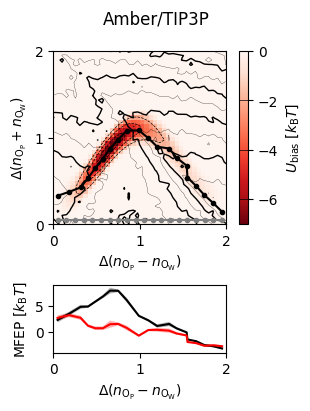

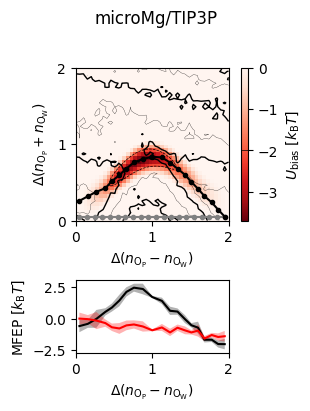

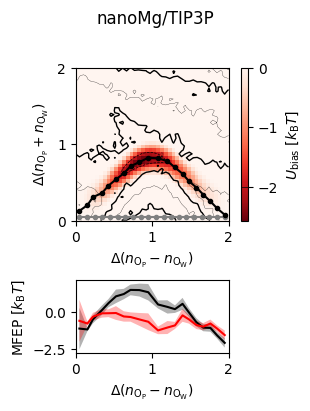

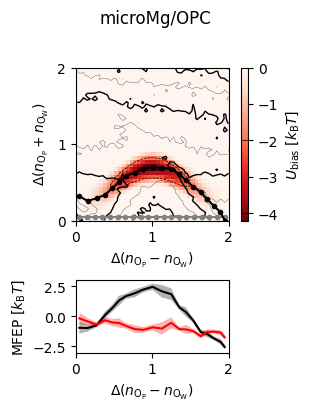

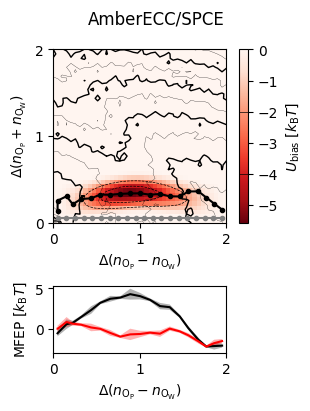

In [17]:
for ff in FORCEFIELDS_ARCHIVE:
    fig, (ax1, ax2) = plt.subplots(nrows=2, height_ratios=(3, 1), sharex=True, figsize=(3, 4), constrained_layout=True)
    plot_bias_on_fes_mfep(PROJECT_DIR / f'metad/archive/op_{ff}', ax1)
    plot_barrier_mfep(PROJECT_DIR / f'metad/archive/op_{ff}', ax2)
    fig.suptitle(LABELS[ff])
    plt.savefig(f'figures/biasfitting/archive/barrier_mfep_{ff}.pdf')

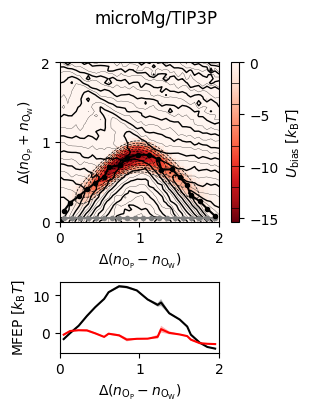

In [18]:
for ff in FORCEFIELDS:
    fig, (ax1, ax2) = plt.subplots(nrows=2, height_ratios=(3, 1), sharex=True, figsize=(3, 4), constrained_layout=True)
    plot_bias_on_fes_mfep(PROJECT_DIR / f'metad/op_{ff}', ax1)
    plot_barrier_mfep(PROJECT_DIR / f'metad/op_{ff}', ax2)
    fig.suptitle(LABELS[ff])
    plt.savefig(f'figures/biasfitting/barrier_mfep_{ff}.pdf')